# Machine Translation with Transformers

Corpora: WMT 2024
Le programme semble marcher. C'est le plus rapide jusqu'à présent.
Valeurs de Vaswani à atteindre :
* 27,3 avec base, faisceau et moyenne sur le test
* 25,8 avec base et faisceau sur la validation

This program obtained better results, but it is now very, very slow with macOS 27

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

In [2]:
import sys
import torch
import torch.nn as nn
from torch.nn import Transformer
from torch import Tensor
from torch.nn.utils.rnn import pad_sequence
import random
from torch.optim.lr_scheduler import LambdaLR
import numpy as np
import math
import matplotlib.pyplot as plt
from tqdm import tqdm
import sentencepiece as spm
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import json
import pandas as pd
import itertools
from timeit import default_timer as timer
from torch.utils.data import BatchSampler
import sacrebleu

In [3]:
import torch._dynamo
torch._dynamo.config.capture_scalar_outputs = True

In [4]:
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

In [5]:
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else
                      'cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

device(type='mps')

In [6]:
# DEVICE = 'cpu'

In [7]:
MAX_TOKEN_LEN = 256  # fairseq ne limite pas la longueur ici (pas de
# --max-source-positions / --max-target-positions dans la commande) ;
# 256 est une marge large qui ne tronque plus les phrases WMT en-de.

In [8]:
EMB_SIZE = 512
NHEAD = 8
FFN_HID_DIM = 4 * EMB_SIZE
NUM_ENCODER_LAYERS = 6
NUM_DECODER_LAYERS = 6

BATCH_SIZE = 24  # 32 : 6,30 (en fait plus), 64 : 15 24 : 6,50
# ACCU_CNT = 26

## Dataset

In [9]:
data_dir = Path('wmt14')

In [10]:
train_src = data_dir / 'train.en'
train_tgt = data_dir / 'train.de'
val_src = data_dir / 'validation.en'
val_tgt = data_dir / 'validation.de'
test_src = data_dir / 'test.en'
test_tgt = data_dir / 'test.de'

In [11]:
train = data_dir / 'train.json'
val = data_dir / 'validation.json'
test = data_dir / 'test.json'

In [12]:
print(f"Loading {train}...")
train_dict = pd.read_json(train, lines=True).to_dict(orient='records')
print(f"Loading {val}...")
val_dict = pd.read_json(val, lines=True).to_dict(orient='records')
print(f"Loading {test}...")
test_dict = pd.read_json(test, lines=True).to_dict(orient='records')

Loading wmt14/train.json...
Loading wmt14/validation.json...
Loading wmt14/test.json...


In [13]:
train_input_texts = [item['translation']['en'].strip() for item in train_dict]
train_target_texts = [item['translation']['de'].strip() for item in train_dict]

In [14]:
val_input_texts = [item['translation']['en'].strip() for item in val_dict]
val_target_texts = [item['translation']['de'].strip() for item in val_dict]

In [15]:
test_input_texts = [item['translation']['en'].strip() for item in test_dict]
test_target_texts = [item['translation']['de'].strip() for item in test_dict]

In [16]:
train_target_texts[:2]

['Wiederaufnahme der Sitzungsperiode',
 'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.']

In [17]:
len(train_input_texts), len(train_target_texts), len(
    val_input_texts), len(val_target_texts), len(test_input_texts), len(test_target_texts)

(4508785, 4508785, 3000, 3000, 3003, 3003)

In [18]:
print(train_input_texts[1000])
print(train_target_texts[1000])
print(val_input_texts[1000])
print(val_target_texts[1000])
print(test_input_texts[1000])
print(test_target_texts[1000])

In this respect, we should heed the words of von Eieck, and doubtless also those of the great Italian liberal Bruno Leoni, who warned precisely against the risks of an abnormal increase in anti-competition policies.
In dieser Hinsicht dürften wohl die Schriften von von Eieck und sicherlich auch die eines bedeutenden italienischen Liberalen wie Bruno Leoni hilfreich für uns sein, der eben vor den Gefahren einer außergewöhnlichen Zunahme politischer Maßnahmen gegen wettbewerbswidrige Praktiken warnte.
NKU Head: Svarc System audit has failed because of politicians.
NKÚ-Chef: Kontrolle des Schwarz-Systems versagt durch Verschulden der Politik
Drama in Uruguay: Boys kill playmate with machetes
Drama in Uruguay: Jungen töten Spielkamderaden mit Machete


In [19]:
num_samples = len(train_input_texts)
num_samples

4508785

In [20]:
# Running in a notebook hangs the cell. Run it from an external program
# spm.SentencePieceTrainer.train('--input=all_texts.txt --model_prefix=m --vocab_size=13700 --model_type=bpe --pad_id=3,logstream=sys.stdout')

In [21]:
sp = spm.SentencePieceProcessor()
sp.load(str(data_dir / 'spm.model'))

True

In [22]:
VOCAB_SIZE = len(sp)
VOCAB_SIZE

37000

In [23]:
UNK_IDX, BOS_IDX, EOS_IDX, PAD_IDX = sp.unk_id(
), sp.bos_id(), sp.eos_id(), sp.pad_id()
UNK_IDX, BOS_IDX, EOS_IDX, PAD_IDX

(1, 2, 3, 0)

In [24]:
def text2codes(texts, sp, max_len=MAX_TOKEN_LEN):
    codes = []
    for text in texts:
        # add_bos=True, add_eos=True pour ajouter BOS et EOS
        code = sp.encode(text, out_type=int, add_bos=True,
                         add_eos=True)[:max_len]
        codes.append(torch.tensor(code))
    return codes

In [25]:
train_input_texts[:3], train_target_texts[:3]

(['Resumption of the session',
  'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
  "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."],
 ['Wiederaufnahme der Sitzungsperiode',
  'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.',
  'Wie Sie feststellen konnten, ist der gefürchtete "Millenium-Bug " nicht eingetreten. Doch sind Bürger einiger unserer Mitgliedstaaten Opfer von schrecklichen Naturkatastrophen geworden.'])

In [26]:
text2codes(train_input_texts[:3], sp)

[tensor([    2,  2363, 27628,   304,   279,  9804,     3]),
 tensor([    2,   320, 18524, 24229,   279,  9804,   304,   279,   662,  1103,
         11487,  5293,   314,   382, 13058,  2643,  6046, 18095,   310,   320,
           794,   964,  3371,  1224,   311,  2608,   533,   263,  6878,   876,
           956,   285,   279,  2563,   391,   533, 13424,   263,  8146,  1713,
           488,  3086, 33413,     3]),
 tensor([    2,  6651, 33412,   441,   533,   536,   518,  4696, 33412,   279,
           265,  1548,   314,  1286, 33406,   430,   622,  1384, 17402, 33454,
          9825,   311,  3230,   631, 33412,  1827,   279,  1113,   285,   263,
          1669,   304,  1174, 14612,   263,  5521,   304,  4021, 15095,   391,
          9296,  1114,   265,  1548,  1311, 33413,     3])]

In [27]:
text2codes(train_target_texts[:3], sp)

[tensor([    2, 27577,   317, 26416,     3]),
 tensor([    2,   762, 32508,   315,   634, 14134, 33412,   480, 11197,  6176,
         18395, 33393, 26416,   431,  1084,  2319,   427, 27751,  2331, 33412,
         15635,  1361, 11016,  2950, 18884,   803,  3749, 10102,   318,  4349,
         33412,   926,   491, 10227,  5683,  4732, 33413,     3]),
 tensor([    2,  1778,   491,  9339,  6488, 33412,   420,   317,  2231,   376,
           824,   289,   666, 33425, 20670,  1384, 33429, 33428,   500,   666,
           495, 28247, 33413,  4722,   575,  1905,  9396,  1576,  1421,  7304,
           405, 27970,  3362, 21659,  6537, 33413,     3])]

In [28]:
def codes2text(codes, sp):
    texts = []
    for code in codes:
        # Pas besoin d'option spéciale pour le décodage
        text = sp.decode(code.tolist())
        texts.append(text)
    return texts

In [29]:
codes2text(text2codes(train_input_texts[:3], sp), sp)

['Resumption of the session',
 'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
 "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."]

In [30]:
class PositionalEncoding(nn.Module):
    def __init__(self,
                 emb_size: int,
                 dropout: float,
                 maxlen: int = 5000):
        super().__init__()
        self.scale = emb_size ** 0.5
        den = torch.exp(- torch.arange(0, emb_size, 2)
                        * math.log(10000) / emb_size)
        pos = torch.arange(0, maxlen).reshape(maxlen, 1)
        pos_embedding = torch.zeros((maxlen, emb_size))
        pos_embedding[:, 0::2] = torch.sin(pos * den)
        pos_embedding[:, 1::2] = torch.cos(pos * den)
        pos_embedding = pos_embedding.unsqueeze(0)
        self.dropout = nn.Dropout(dropout)
        # Forcez impérativement le type dans le __init__ de PositionalEncoding
        self.register_buffer('pos_embedding', pos_embedding)
        self.emb_size = emb_size

    def forward(self, token_embedding: Tensor):
        return self.dropout(
            token_embedding * self.scale +
            self.pos_embedding[:, :token_embedding.size(1), :]
        )
        """def forward(self, token_embedding: Tensor):
        # On crée une copie contiguë du masque de position pour le GPU
        pos = self.pos_embedding[:, :token_embedding.size(1), :].clone().contiguous()
        return self.dropout(token_embedding * self.scale + pos)
        """

In [31]:
pe = PositionalEncoding(10, 0.1)

In [32]:
torch.zeros(1, 5, 10)

tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]])

In [33]:
pe(torch.zeros(1, 5, 10))

tensor([[[ 0.0000e+00,  1.1111e+00,  0.0000e+00,  1.1111e+00,  0.0000e+00,
           1.1111e+00,  0.0000e+00,  1.1111e+00,  0.0000e+00,  0.0000e+00],
         [ 9.3497e-01,  6.0034e-01,  1.7536e-01,  1.0972e+00,  2.7907e-02,
           1.1108e+00,  4.4234e-03,  1.1111e+00,  7.0106e-04,  1.1111e+00],
         [ 1.0103e+00, -4.6239e-01,  3.4633e-01,  1.0558e+00,  5.5796e-02,
           1.1097e+00,  8.8467e-03,  1.1111e+00,  1.4021e-03,  1.1111e+00],
         [ 0.0000e+00, -1.1000e+00,  5.0862e-01,  9.8787e-01,  8.3650e-02,
           0.0000e+00,  1.3270e-02,  1.1110e+00,  2.1032e-03,  1.1111e+00],
         [-8.4089e-01, -7.2627e-01,  0.0000e+00,  8.9521e-01,  1.1145e-01,
           1.1055e+00,  1.7693e-02,  1.1110e+00,  2.8043e-03,  1.1111e+00]]])

In [34]:
class Seq2SeqTransformer(nn.Module):
    def __init__(self,
                 num_encoder_layers: int,
                 num_decoder_layers: int,
                 emb_size: int,
                 nhead: int,
                 vocab_size: int,
                 dim_feedforward: int = 2048,
                 dropout: float = 0.1):
        super().__init__()
        self.transformer = Transformer(d_model=emb_size,
                                       nhead=nhead,
                                       num_encoder_layers=num_encoder_layers,
                                       num_decoder_layers=num_decoder_layers,
                                       dim_feedforward=dim_feedforward,
                                       dropout=dropout,
                                       batch_first=True)

        self.emb_size = emb_size
        self.embedding = nn.Embedding(
            vocab_size, emb_size, padding_idx=PAD_IDX)
        self.positional_encoding = PositionalEncoding(
            emb_size, dropout=dropout)

        self.generator = nn.Linear(emb_size, vocab_size, bias=False)
        self.generator.weight = self.embedding.weight

    def forward(self,
                src: Tensor,
                trg: Tensor,
                src_mask: Tensor,
                tgt_mask: Tensor,
                src_padding_mask: Tensor,
                tgt_padding_mask: Tensor,
                memory_key_padding_mask: Tensor):
        src_emb = self.positional_encoding(self.embedding(src))
        tgt_emb = self.positional_encoding(self.embedding(trg))
        outs = self.transformer(src_emb, tgt_emb,
                                src_mask=None,
                                tgt_mask=tgt_mask,
                                memory_mask=None,
                                src_key_padding_mask=src_padding_mask,
                                tgt_key_padding_mask=tgt_padding_mask,
                                memory_key_padding_mask=memory_key_padding_mask)
                                #tgt_is_causal=True)

        return self.generator(outs)

    def encode(self, src: Tensor, src_mask: Tensor):
        return self.transformer.encoder(self.positional_encoding(
            self.embedding(src)), src_mask)

    def decode(self, tgt: Tensor, memory: Tensor, tgt_mask: Tensor):
        return self.transformer.decoder(self.positional_encoding(
            self.embedding(tgt)), memory,
            tgt_mask)

In [35]:
nn.Transformer.generate_square_subsequent_mask(10)

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [36]:
def create_mask(src, tgt, pad_idx=PAD_IDX):
    tgt_seq_len = tgt.shape[-1]
    # Génère le masque directement sur le device de tgt
    tgt_mask = nn.Transformer.generate_square_subsequent_mask(
        tgt_seq_len).to(tgt.device).bool()
    # Il est déjà float (0 et -inf), mais on peut le garder ainsi
    src_padding_mask = (src == pad_idx).to(tgt.device)
    tgt_padding_mask = (tgt == pad_idx).to(tgt.device)
    return None, tgt_mask, src_padding_mask, tgt_padding_mask

In [37]:
src = pad_sequence(text2codes(
    train_input_texts[:3], sp), batch_first=True, padding_value=PAD_IDX)
tgt = pad_sequence(text2codes(
    train_target_texts[:3], sp), batch_first=True, padding_value=PAD_IDX)

In [38]:
train_input_texts[:3], train_target_texts[:3]

(['Resumption of the session',
  'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
  "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."],
 ['Wiederaufnahme der Sitzungsperiode',
  'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.',
  'Wie Sie feststellen konnten, ist der gefürchtete "Millenium-Bug " nicht eingetreten. Doch sind Bürger einiger unserer Mitgliedstaaten Opfer von schrecklichen Naturkatastrophen geworden.'])

In [39]:
src

tensor([[    2,  2363, 27628,   304,   279,  9804,     3,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    2,   320, 18524, 24229,   279,  9804,   304,   279,   662,  1103,
         11487,  5293,   314,   382, 13058,  2643,  6046, 18095,   310,   320,
           794,   964,  3371,  1224,   311,  2608,   533,   263,  6878,   876,
           956,   285,   279,  2563,   391,   533, 13424,   263,  8146,  1713,
           488,  3086, 33413,     3,     0,     0,     0],
        [    2,  6651, 33412,   441,   533,   536,   518,  4696, 33412,   279,
           265,  1548,   314,  1286, 33406,   430,   622,  1384, 17402, 33454,
          9825,   311,  3230,   631, 33412,  1827,   279,  1113,   285,   263,
          166

In [40]:
tgt

tensor([[    2, 27577,   317, 26416,     3,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0],
        [    2,   762, 32508,   315,   634, 14134, 33412,   480, 11197,  6176,
         18395, 33393, 26416,   431,  1084,  2319,   427, 27751,  2331, 33412,
         15635,  1361, 11016,  2950, 18884,   803,  3749, 10102,   318,  4349,
         33412,   926,   491, 10227,  5683,  4732, 33413,     3],
        [    2,  1778,   491,  9339,  6488, 33412,   420,   317,  2231,   376,
           824,   289,   666, 33425, 20670,  1384, 33429, 33428,   500,   666,
           495, 28247, 33413,  4722,   575,  1905,  9396,  1576,  1421,  7304,
           405, 27970,  3362, 21659,  6537, 33413,     3,     0]])

In [41]:
create_mask(src, tgt)

(None,
 tensor([[False,  True,  True,  ...,  True,  True,  True],
         [False, False,  True,  ...,  True,  True,  True],
         [False, False, False,  ...,  True,  True,  True],
         ...,
         [False, False, False,  ..., False,  True,  True],
         [False, False, False,  ..., False, False,  True],
         [False, False, False,  ..., False, False, False]]),
 tensor([[False, False, False, False, False, False, False,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True],
         [False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
   

In [42]:
def rate(step, model_size, factor, warmup):
    if step == 0:
        step = 1
    return factor * (
        model_size ** (-0.5) * min(step ** (-0.5), step * warmup ** (-1.5))
    )

In [43]:
transformer = Seq2SeqTransformer(NUM_ENCODER_LAYERS, NUM_DECODER_LAYERS, EMB_SIZE,
                                 NHEAD, VOCAB_SIZE, FFN_HID_DIM)

for p in transformer.parameters():
    if p.dim() > 1:
        nn.init.xavier_uniform_(p)

transformer.to(DEVICE)
# Le fastpath 'nested tensor' de nn.TransformerEncoder tente de verifier
# l'alignement du masque via un op non supporte sur MPS
# (aten::_nested_tensor_from_mask_left_aligned), ce qui force un aller-
# retour CPU a chaque forward. On desactive ce chemin : sur MPS il n'apporte
# aucun gain de toute facon.
transformer.transformer.encoder.enable_nested_tensor = False
transformer.transformer.encoder.gradient_checkpointing = True
transformer.transformer.decoder.gradient_checkpointing = True
#transformer = torch.compile(transformer, mode='reduce-overhead')
transformer = torch.compile(transformer, mode='default')
#transformer = torch.compile(transformer)

# reduction='sum' : on ne normalise plus ici. train_step_variable accumule les
# gradients de tous les micro-batches d'un pas puis divise UNE SEULE FOIS par
# le nombre reel de tokens cible vus dans le pas (facon fairseq --max-tokens).
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1, reduction='sum')

optimizer = torch.optim.Adam(
    transformer.parameters(), lr=1, betas=(0.9, 0.98), eps=1e-9
)
lr_scheduler = LambdaLR(
    optimizer=optimizer,
    lr_lambda=lambda step: rate(
        step, model_size=transformer.emb_size, factor=1.0, warmup=4000
    ),
)

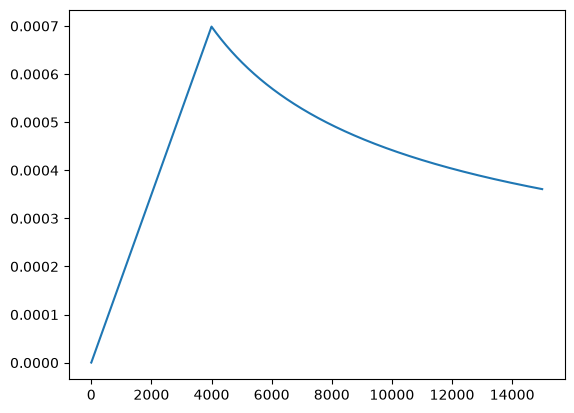

In [44]:
plt.plot([rate(i, transformer.emb_size, 1.0, 4000)
         for i in range(0, 15*1000)])

In [45]:
class PairDataset(Dataset):
    def __init__(self, input_texts, target_texts, sp, max_len=MAX_TOKEN_LEN):
        self.sp = sp
        self.max_len = max_len

        # On encode entièrement (sans troncature) pour connaître la vraie
        # longueur de chaque phrase, puis on ÉCARTE les paires qui dépassent
        # max_len au lieu de les tronquer. Tronquer après add_eos=True
        # supprime l'EOS et coupe la cible en plein milieu : le modèle
        # apprend alors des séquences qui ne se terminent jamais proprement.
        # fairseq filtre ces exemples (max-source-positions /
        # max-target-positions), il ne les tronque jamais : on fait pareil.
        self.input_texts = []
        self.target_texts = []
        self.lengths = []

        n_dropped = 0
        for src_text, tgt_text in zip(input_texts, target_texts):
            src_len = len(sp.encode(src_text, out_type=int,
                          add_bos=True, add_eos=True))
            tgt_len = len(sp.encode(tgt_text, out_type=int,
                          add_bos=True, add_eos=True))
            if src_len <= max_len and tgt_len <= max_len:
                self.input_texts.append(src_text)
                self.target_texts.append(tgt_text)
                self.lengths.append(max(src_len, tgt_len))
            else:
                n_dropped += 1

        print(f"PairDataset: {n_dropped} paires écartées (> {max_len} tokens) "
              f"sur {len(input_texts)}, {len(self.input_texts)} conservées.")

    def __len__(self):
        return len(self.input_texts)

    def __getitem__(self, idx):
        # Plus besoin de [:max_len] ici : tout ce qui est conservé tient
        # déjà dans max_len, EOS inclus.
        src = torch.tensor(self.sp.encode(
            self.input_texts[idx], out_type=int, add_bos=True, add_eos=True))
        tgt = torch.tensor(self.sp.encode(
            self.target_texts[idx], out_type=int, add_bos=True, add_eos=True))
        return src, tgt, self.lengths[idx]   # on retourne aussi la longueur

In [46]:
class BucketBatchSampler(BatchSampler):
    def __init__(self, lengths, batch_size, bucket_boundaries=None, shuffle=True, drop_last=False):
        self.lengths = lengths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last
        if bucket_boundaries is None:
            bucket_boundaries = list(range(10, MAX_TOKEN_LEN+1, 10))
        self.bucket_boundaries = bucket_boundaries
        self.buckets = self._create_buckets()

    def _create_buckets(self):
        buckets = [[] for _ in range(len(self.bucket_boundaries)+1)]
        for idx, l in enumerate(self.lengths):
            placed = False
            for i, boundary in enumerate(self.bucket_boundaries):
                if l <= boundary:
                    buckets[i].append(idx)
                    placed = True
                    break
            if not placed:
                buckets[-1].append(idx)
        return [b for b in buckets if len(b) > 0]

    def __iter__(self):
        all_batches = []
        for bucket in self.buckets:
            if self.shuffle:
                indices = torch.randperm(len(bucket)).tolist()
                bucket = [bucket[i] for i in indices]
            for i in range(0, len(bucket), self.batch_size):
                batch = bucket[i:i+self.batch_size]
                if len(batch) == self.batch_size or not self.drop_last:
                    all_batches.append(batch)
        if self.shuffle:
            # Mélange global de tous les batches
            random.shuffle(all_batches)
        for batch in all_batches:
            yield batch

    def __len__(self):
        total = 0
        for bucket in self.buckets:
            total += len(bucket) // self.batch_size
        return total

In [47]:
train_dataset = PairDataset(train_input_texts, train_target_texts, sp)
bucket_sampler = BucketBatchSampler(
    lengths=train_dataset.lengths,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)
train_dataloader = DataLoader(
    train_dataset,
    batch_sampler=bucket_sampler,
    collate_fn=lambda batch: (
        pad_sequence([b[0] for b in batch], batch_first=True,
                     padding_value=PAD_IDX),
        pad_sequence([b[1] for b in batch],
                     batch_first=True, padding_value=PAD_IDX)
    ),
    pin_memory=False
)

PairDataset: 1243 paires écartées (> 256 tokens) sur 4508785, 4507542 conservées.


In [48]:
val_dataset = PairDataset(val_input_texts, val_target_texts, sp)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    collate_fn=lambda batch: (
        pad_sequence([b[0] for b in batch], batch_first=True,
                     padding_value=PAD_IDX),
        pad_sequence([b[1] for b in batch],
                     batch_first=True, padding_value=PAD_IDX)
    ),
    pin_memory=False
)

PairDataset: 0 paires écartées (> 256 tokens) sur 3000, 3000 conservées.


In [49]:
def train_step_variable(model, optimizer, train_iter, dataloader, target_tokens_per_step, loss_fn, PAD_IDX, DEVICE):
    model.train()
    # Accumulation en tenseurs sur le device : on evite les .item() (donc les
    # synchronisations MPS) a chaque micro-batch, un seul aller-retour CPU en
    # fin de pas.
    total_loss = torch.zeros((), device=DEVICE)      # somme brute des loss, pour affichage
    total_correct = torch.zeros((), device=DEVICE)
    total_tokens = torch.zeros((), device=DEVICE)     # tokens CIBLE, pour affichage
    optimizer.zero_grad()

    accu_tokens = 0        # budget "facon fairseq" : max(longueur src, longueur tgt) par phrase, somme sur le batch
    accu_tgt_tokens = 0    # tokens CIBLE uniquement : normalisation du gradient
    steps_done = 0

    while accu_tokens < target_tokens_per_step:
        try:
            src, tgt = next(train_iter)
        except StopIteration:
            train_iter = iter(dataloader)
            src, tgt = next(train_iter)

        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        tgt_input, tgt_out = tgt[:, :-1], tgt[:, 1:]

        mask = (tgt_out != PAD_IDX)
        tgt_tokens_t = mask.sum()

        # fairseq (--max-tokens) ne compte pas src+tgt : pour chaque phrase du
        # batch il prend max(longueur_src, longueur_tgt), puis somme sur le
        # batch. Comme src et tgt ont des longueurs proches en en-de apres
        # BPE, ca revient a peu pres a compter les tokens cible seuls - c'est
        # pour ca que la version originale (tgt seul) etait deja une bonne
        # approximation. On reproduit ici la formule exacte de fairseq :
        src_lens = (src != PAD_IDX).sum(dim=1)   # longueur par phrase, cote source
        tgt_lens = mask.sum(dim=1)                # longueur par phrase, cote cible
        batch_tokens_t = torch.maximum(src_lens, tgt_lens).sum()

        src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
            src, tgt_input)

        # Forward avec eventuel autocast (decommente si necessaire)
        #with torch.autocast(device_type='mps', dtype=torch.float16):
        logits = model(src, tgt_input, src_mask, tgt_mask,
                    src_padding_mask, tgt_padding_mask,
                    memory_key_padding_mask=src_padding_mask)

        # loss_fn est en reduction='sum' : loss brute (non normalisee) pour ce
        # micro-batch. backward() ACCUMULE les gradients a chaque appel ; sommer
        # les loss brutes sur tous les micro-batches puis diviser une seule fois
        # a la fin equivaut exactement a calculer la loss sur le batch entier
        # d'un coup, sans jamais materialiser ce batch entier en memoire.
        loss = loss_fn(logits.reshape(-1, logits.size(-1)),
                    tgt_out.reshape(-1))
        # end with autocast
        loss.backward()

        with torch.no_grad():
            total_loss += loss.detach()
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == tgt_out) & mask).sum()
            total_tokens += tgt_tokens_t

        del logits, loss
        accu_tokens += int(batch_tokens_t)
        accu_tgt_tokens += int(tgt_tokens_t)
        steps_done += 1

    # Normalisation facon fairseq : diviser le gradient accumule par le nombre
    # REEL de tokens cible vus dans ce pas.
    for p in model.parameters():
        if p.grad is not None:
            p.grad.div_(max(accu_tgt_tokens, 1))

    optimizer.step()
    if lr_scheduler:
        lr_scheduler.step()
    optimizer.zero_grad()

    avg_loss = (total_loss / total_tokens).item() if total_tokens > 0 else 0
    accuracy = (total_correct / total_tokens).item() if total_tokens > 0 else 0
    return avg_loss, accuracy, train_iter

In [50]:
def evaluate(model, dataloader, loss_fn, PAD_IDX, DEVICE, max_batches=None):
    """
    Évalue le modèle sur le dataloader.
    max_batches: Permet d'évaluer sur un sous-ensemble pour aller plus vite entre les steps.
    """
    model.eval()
    total_loss = 0
    total_correct = 0
    total_tokens = 0

    # On désactive le calcul du gradient pour économiser la mémoire de la M3
    with torch.no_grad():
        for i, (src, tgt) in enumerate(dataloader):
            if max_batches and i >= max_batches:
                break

            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            tgt_input = tgt[:, :-1]
            tgt_out = tgt[:, 1:]

            # Recréation des masques (sans training, seul le padding et le masque causal comptent)
            src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
                src, tgt_input)

            logits = model(
                src=src,
                trg=tgt_input,
                src_mask=src_mask,
                tgt_mask=tgt_mask,
                src_padding_mask=src_padding_mask,
                tgt_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=src_padding_mask
            )

            mask = (tgt_out != PAD_IDX)
            n_tok = mask.sum().item()

            # loss_fn est en reduction='sum' (voir cellule d'instanciation du
            # modèle) : on ramène nous-mêmes la loss du batch à une moyenne
            # par token cible, pour rester comparable à avant et à
            # train_step_variable.
            loss = loss_fn(logits.reshape(-1, logits.size(-1)),
                           tgt_out.reshape(-1))

            total_loss += loss.item()

            # Précision (en ignorant le padding)
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == tgt_out) & mask).sum().item()
            total_tokens += n_tok

        avg_loss = total_loss / total_tokens if total_tokens > 0 else 0
        accuracy = total_correct / total_tokens if total_tokens > 0 else 0
        return avg_loss, accuracy

In [51]:
reprise = False

In [52]:
def load_checkpoint(path, model, optimizer, scheduler=None):
    checkpoint = torch.load(path, map_location=DEVICE)

    # Restauration des poids du modèle
    model.load_state_dict(checkpoint['model_state_dict'])

    # Restauration de l'état de l'optimiseur
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    # Restauration du step actuel
    start_step = checkpoint['step']

    # Restauration du scheduler si présent
    if scheduler and 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    print(f"Reprise de l'entraînement au step {start_step}")
    return start_step

# --- Utilisation ---
# start_step = load_checkpoint(PATH_SAVE, transformer, optimizer, lr_scheduler)
# for step in tqdm(range(start_step + 1, NUM_STEPS + 1)):
#     ...

In [53]:
import os
from tqdm import tqdm
from timeit import default_timer as timer

# Configuration
NUM_STEPS = 100000
VAL_EVERY = 1400
VAL_BATCHES = 50
PATH_SAVE_BEST = "best_model_transformer.pt"
# les fichiers seront checkpoint_step_1000.pt, ...
CHECKPOINT_PREFIX = "checkpoint_step_"
# optionnel : pour ranger dans un dossier
os.makedirs("checkpoints", exist_ok=True)

train_losses, train_accs = [], []
val_losses, val_accs = [], []
best_val_loss = float('inf')
train_iter = iter(train_dataloader)

# Liste pour garder les 5 derniers chemins de checkpoints
checkpoint_paths = []

# Pour la reprise à partir du meilleur modèle sauvegardé (si existe), on charge le checkpoint et on récupère le step de départ
if reprise:
    start_step = load_checkpoint(
        PATH_SAVE_BEST, transformer, optimizer, lr_scheduler)
else:
    start_step = 0

# Pour l'ajustement initial du step de départ (si on reprend d'un checkpoint, on continue à partir de ce step)
#for step in tqdm(range(1, NUM_STEPS + 1)):
for step in tqdm(range(start_step + 1, NUM_STEPS + 1)):
    start_time = timer()

    # 1. Pas d'entraînement
    # Aligné sur la commande fairseq : --max-tokens 4096 --update-freq 8
    # => 4096 * 8 = 32768 tokens par mise à jour d'optimiseur
    target_tokens = 32768
    train_loss, train_acc, train_iter = train_step_variable(
        transformer, optimizer, train_iter, train_dataloader,
        target_tokens, loss_fn, PAD_IDX, DEVICE
    )

    train_losses.append(train_loss)
    train_accs.append(train_acc)

    end_time = timer()

    # 2. Affichage périodique
    if step % 1000 == 0:
        print(
            f"\n[Step {step}] Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Time: {(end_time-start_time):.2f}s")

    # 3. Évaluation et Sauvegarde
    if step % VAL_EVERY == 0:
        v_loss, v_acc = evaluate(
            transformer, val_dataloader, loss_fn, PAD_IDX, DEVICE, max_batches=VAL_BATCHES)
        val_losses.append(v_loss)
        val_accs.append(v_acc)

        print(
            f">>> EVALUATION | Val Loss: {v_loss:.4f} | Val Acc: {v_acc:.4f}")

        # ---------- Sauvegarde du checkpoint périodique (tous les VAL_EVERY pas) ----------
        checkpoint_path = f"checkpoints/{CHECKPOINT_PREFIX}{step}.pt"
        torch.save({
            'step': step,
            'model_state_dict': transformer.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': lr_scheduler.state_dict(),
            'loss': v_loss,
        }, checkpoint_path)
        checkpoint_paths.append(checkpoint_path)

        # Conserver au maximum 5 checkpoints (supprimer le plus ancien)
        if len(checkpoint_paths) > 5:
            oldest = checkpoint_paths.pop(0)
            if os.path.exists(oldest):
                os.remove(oldest)

        # ---------- Sauvegarde du meilleur modèle (validation loss la plus basse) ----------
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save({
                'step': step,
                'model_state_dict': transformer.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': lr_scheduler.state_dict(),
                'loss': v_loss,
            }, PATH_SAVE_BEST)
            print(
                f"*** Nouveau record ! Modèle sauvegardé sous : {PATH_SAVE_BEST} ***")

        # Libération de la mémoire sur Mac M3
        if DEVICE == 'mps':
            torch.mps.empty_cache()

  1%|          | 1000/100000 [2:36:57<233:55:28,  8.51s/it]


[Step 1000] Loss: 6.5193 | Acc: 0.1666 | Time: 7.82s


  1%|▏         | 1399/100000 [3:31:01<213:12:33,  7.78s/it]/opt/anaconda3/lib/python3.14/site-packages/torch/nn/modules/transformer.py:480: UserWarning: The operator 'aten::_nested_tensor_from_mask_left_aligned' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/mps/MPSFallback.mm:34.)
  elif do_mask_check and not torch._nested_tensor_from_mask_left_aligned(


>>> EVALUATION | Val Loss: 5.8661 | Val Acc: 0.2339


  1%|▏         | 1400/100000 [3:31:18<289:26:49, 10.57s/it]

*** Nouveau record ! Modèle sauvegardé sous : best_model_transformer.pt ***


... (398 outputs left out)

 99%|█████████▉| 99399/100000 [239:44:11<1:29:21,  8.92s/it]

>>> EVALUATION | Val Loss: 2.9280 | Val Acc: 0.6477


100%|██████████| 100000/100000 [241:05:33<00:00,  8.68s/it] 


[Step 100000] Loss: 3.1344 | Acc: 0.6173 | Time: 7.97s


In [61]:
checkpoint_path = f"checkpoints/{CHECKPOINT_PREFIX}{step}.pt"
torch.save({
    'step': step,
    'model_state_dict': transformer.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': lr_scheduler.state_dict(),
    'loss': v_loss,
}, checkpoint_path)

In [62]:
train_losses, val_losses

([10.542890548706055,
  10.543776512145996,
  10.545123100280762,
  10.542508125305176,
  10.540691375732422,
  10.535888671875,
  10.534501075744629,
  10.531484603881836,
  10.52861499786377,
  10.524592399597168,
  10.517481803894043,
  10.510970115661621,
  10.507603645324707,
  10.501714706420898,
  10.492432594299316,
  10.487605094909668,
  10.48137378692627,
  10.471558570861816,
  10.465598106384277,
  10.456099510192871,
  10.445834159851074,
  10.44167423248291,
  10.434236526489258,
  10.42747688293457,
  10.415602684020996,
  10.407947540283203,
  10.400738716125488,
  10.392411231994629,
  10.388092994689941,
  10.381089210510254,
  10.373663902282715,
  10.366726875305176,
  10.361687660217285,
  10.353041648864746,
  10.342930793762207,
  10.33444881439209,
  10.330036163330078,
  10.323617935180664,
  10.3130521774292,
  10.309120178222656,
  10.302026748657227,
  10.298803329467773,
  10.2946138381958,
  10.283483505249023,
  10.28852653503418,
  10.279999732971191,
 

In [63]:
len(train_losses), len(val_losses)

(100000, 71)

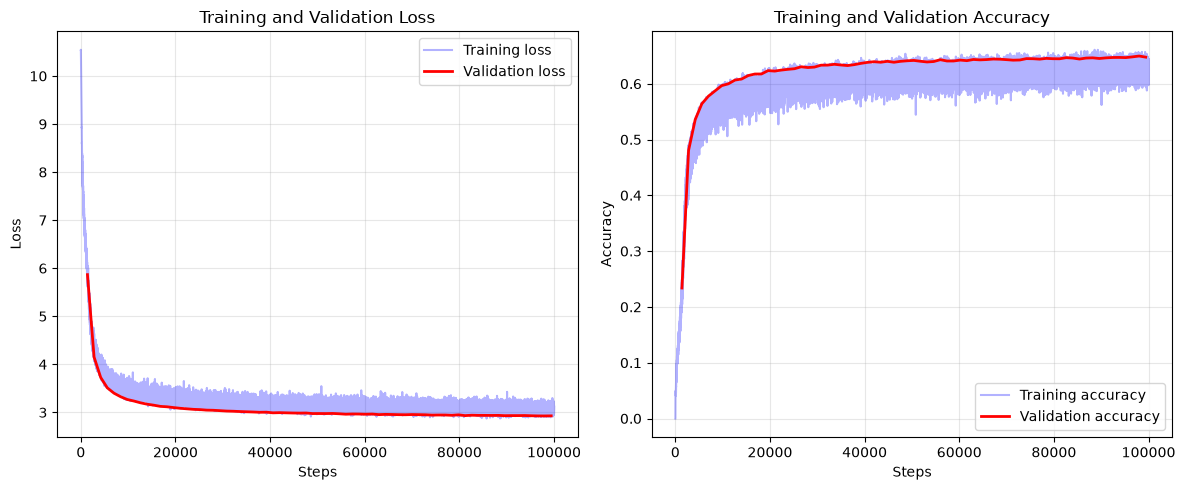

In [64]:
steps = range(len(train_losses))                    # 0 à 99999
val_steps = range(VAL_EVERY, len(train_losses),
                  VAL_EVERY)  # 0, 1000, 2000, ..., 99000

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(steps, train_losses, 'b-', alpha=0.3, label='Training loss')
plt.plot(val_steps, val_losses, 'r-', linewidth=2, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(steps, train_accs, 'b-', alpha=0.3, label='Training accuracy')
plt.plot(val_steps, val_accs, 'r-', linewidth=2, label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Steps')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()